In [2]:
from pathlib import Path
import pandas as pd

csv = max(Path("../results/runs").glob("*/results.csv"))  # último resultados.csv
csv

WindowsPath('../results/runs/tournament_20250918_214331/results.csv')

In [3]:
df = pd.read_csv(csv)
df.head()

,A,B,pa,pb,seed
0,AlwaysSplit,AlwaysSteal,6,138,1826701614
1,AlwaysSplit,AlwaysSteal,2,134,1367864806
2,AlwaysSplit,AlwaysSteal,2,140,1097657231
3,AlwaysSplit,AlwaysSteal,2,146,579362555
4,AlwaysSplit,AlwaysSteal,8,140,661058651


In [4]:
A = df[["A","pa","pb"]].rename(columns={"A":"name","pa":"score","pb":"opp"})
B = df[["B","pb","pa"]].rename(columns={"B":"name","pb":"score","pa":"opp"})
u = pd.concat([A,B], ignore_index=True)

summary = (u.assign(win=(u.score>u.opp), loss=(u.score<u.opp), tie=(u.score==u.opp))
             .groupby("name", as_index=False)
             .agg(matches=("score","size"),
                  wins=("win","sum"),
                  losses=("loss","sum"),
                  ties=("tie","sum"),
                  mean_payoff=("score","mean"),
                  median_payoff=("score","median"))
             .sort_values(["mean_payoff","wins"], ascending=[False,False]))
summary


,name,matches,wins,losses,ties,mean_payoff,median_payoff
1,AlwaysSteal,20000,19791,14,195,78.38095,79.5
2,TitForTat,20000,8773,9961,1266,53.32360,56.5
0,AlwaysSplit,20000,170,18759,1071,49.00470,48.0


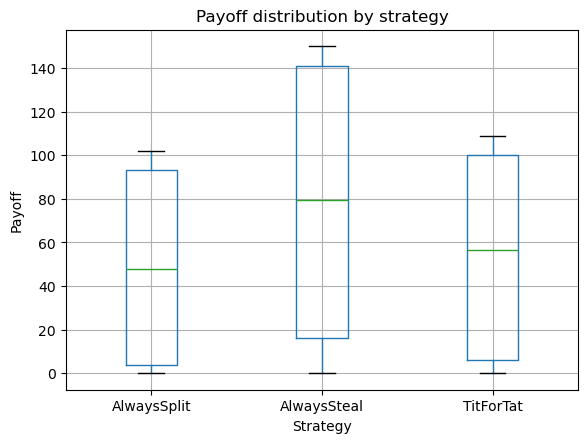

In [5]:
import matplotlib.pyplot as plt

u.boxplot(column="score", by="name", grid=True, rot=0)
plt.title("Payoff distribution by strategy")
plt.suptitle("")  # quita el subtítulo automático
plt.xlabel("Strategy"); plt.ylabel("Payoff")
plt.show()


WindowsPath('../results/figs/payoff_boxplot.png')

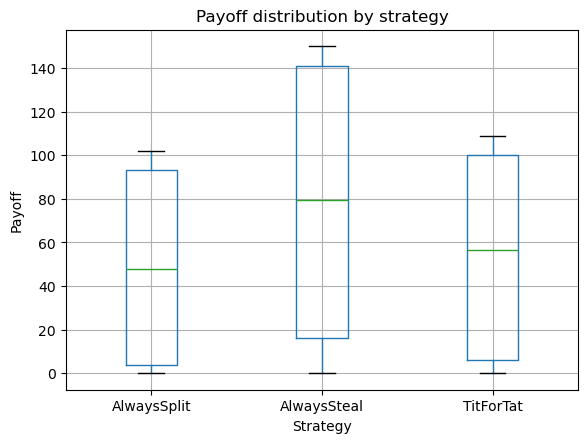

In [6]:
fig_path = Path("../results") / "figs"
fig_path.mkdir(parents=True, exist_ok=True)

ax = u.boxplot(column="score", by="name", grid=True, rot=0)
plt.title("Payoff distribution by strategy"); plt.suptitle("")
plt.xlabel("Strategy"); plt.ylabel("Payoff")
out = fig_path / "payoff_boxplot.png"
plt.savefig(out, dpi=200, bbox_inches="tight")
out
